# IPCA – Análises Avançadas

Neste notebook vamos realizar quatro análises fundamentais:

1. Difusão da inflação  
2. Núcleos de inflação (core inflation)  
3. Heatmap de choques setoriais  
4. Persistência inflacionária (momentum) 

Todas as análises são baseadas nos **subitens**, que são o nível mais granular do IPCA.

## 1. Setup

In [1]:
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)

print("PYTHONPATH atualizado:", ROOT)

import pandas                       as pd
import numpy                        as np
import matplotlib.pyplot            as plt
import matplotlib.dates             as mdates
import seaborn                      as sns
import datetime                     as datetime
from sklearn.linear_model           import LinearRegression
from src.database.connection        import engine

pd.set_option("display.float_format", "{:.6f}".format)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


## 2. Carregar subitens (índice cheio + peso)

In [5]:
query_subitens = """
select
    date::date,
    category        as "idSubItem",
    category_name   as "subItem",
    indice          as "indiceCheio",
    peso,
    (indice * (peso / 100)) as contribuicao
from bcb.ipca_subitens
order by date desc, category;
"""

df = pd.read_sql(query_subitens, engine)
df["date"] = pd.to_datetime(df["date"])
df.head()

,date,idSubItem,subItem,indiceCheio,peso,contribuicao
0,2026-04-01,1101002,Arroz,2.530000,0.493000,0.012473
1,2026-04-01,1101051,Feijão - mulatinho,2.680000,0.012700,0.000340
2,2026-04-01,1101052,Feijão - preto,1.800000,0.038100,0.000686
3,2026-04-01,1101053,Feijão - macáçar (fradinho),0.880000,0.016200,0.000143
4,2026-04-01,1101073,Feijão - carioca (rajado),3.470000,0.125200,0.004344


<br>

---

## ANÁLISE 1 — Difusão da inflação

- Difusão responde:
    > Quantos subitens subiram de preço no mês?

$ \qquad \to$ **Difusão alta** → inflação espalhada  
$ \qquad \to$ **Difusão baixa** → inflação concentrada em poucos itens

|Difusão|$$\to\qquad \frac{ nº \ de \ subitens \ com \ alta }{total \ de \ subitens} $$|
|-|-|

**<u> 🔢 Exemplos numéricos </u>**

| Difusão | Status | Interpretação | Observação|
|-|-|-|-|
| **75%** | Muito alta | $\to\quad$ 3 de cada 4 itens subiram |-|
| **60%** | Alta | $\to\quad$ inflação espalhada | $\to\quad$ muitos itens subindo $\to$ inflação espalhada $\to$ pressão generalizada.|
| **50%** | Moderada | $\to\quad$ metade dos itens subiu | $\to\quad$ inflação moderada $\to$ não totalmente espalhada.|
| **35%** | Baixa | $\to\quad$ inflação concentrada | $\to\quad$ poucos itens subindo $\to$ inflação concentrada $\to$ pressão localizada. |
| **20%** | Muito baixa | $\to\quad$ inflação bem comportada |

In [3]:
df["alta"] = df["indiceCheio"] > 0

df_difusao = (
    df.groupby("date")["alta"].mean().reset_index().rename(columns={"alta": "difusao"})
)

df_difusao["difusao"] *= 100
df_difusao = df_difusao[df_difusao["date"] >= (pd.Timestamp.now() - pd.DateOffset(months=13))]
df_difusao.tail()

,date,difusao
71,2025-12-01,60.477454
72,2026-01-01,63.925729
73,2026-02-01,61.273210
74,2026-03-01,67.374005
75,2026-04-01,65.251989


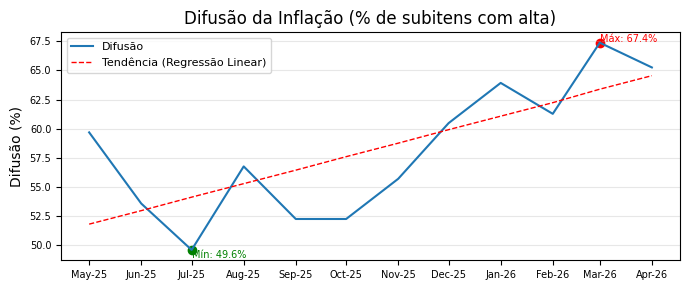

In [5]:
# transformar datas em números (índice)
X = np.arange(len(df_difusao)).reshape(-1, 1)
y = df_difusao["difusao"].values
# modelo de regressão linear (padrão IBM)
modelo = LinearRegression()
modelo.fit(X, y)
# prever valores da tendência
tendencia = modelo.predict(X)
# Máximo e mínimo
max_val = df_difusao["difusao"].max()
min_val = df_difusao["difusao"].min()
max_date = df_difusao.loc[df_difusao["difusao"].idxmax(), "date"]
min_date = df_difusao.loc[df_difusao["difusao"].idxmin(), "date"]

plt.figure(figsize=(7, 3))
plt.plot(df_difusao["date"], df_difusao["difusao"], linewidth=1.5, label="Difusão")
# linha de tendência | Regressão Linear
plt.plot(df_difusao["date"], tendencia, "--", color="red", linewidth=1, label="Tendência (Regressão Linear)")

# Máximo e mínimo
plt.scatter(max_date, max_val, color="red")
plt.text(max_date, max_val + 0.1, f"Máx: {max_val:.1f}%", fontsize=7, color="red")
plt.scatter(min_date, min_val, color="green")
plt.text(min_date, min_val - 0.7, f"Mín: {min_val:.1f}%", fontsize=7, color="green")


plt.title("Difusão da Inflação (% de subitens com alta)")
plt.ylabel("Difusão (%)"); plt.tick_params(axis='y', labelsize=7)
plt.xticks(ticks=df_difusao["date"], labels=df_difusao["date"].dt.strftime("%b-%y"))
plt.tick_params(axis='x', labelsize=7)
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


<br>

___

## ANÁLISE 2 — Núcleos de inflação (média aparada)

Núcleo por média aparada:
- ordena subitens por índice
- remove extremos (ex: 20% mais baixos e 20% mais altos)
- calcula média ponderada do miolo

In [4]:
def trimmed_mean(group: pd.DataFrame, trim: float = 0.2) -> float:
    g = group.sort_values("indiceCheio")
    n = len(g)
    k = int(n * trim)
    if 2 * k >= n:
        return np.nan
    g2 = g.iloc[k : n - k]
    return np.average(g2["indiceCheio"], weights=g2["peso"])

df_trim = (
    df.groupby("date")
    .apply(trimmed_mean)
    .reset_index()
    .rename(columns={0: "nucleo_aparado"})
)
df_trim = df_trim[df_trim["date"] >= (pd.Timestamp.now() - pd.DateOffset(months=13))]
df_trim.tail(13)

,date,nucleo_aparado
65,2025-06-01,0.175539
66,2025-07-01,0.044990
67,2025-08-01,0.232689
68,2025-09-01,0.188179
69,2025-10-01,0.217948
70,2025-11-01,0.173768
71,2025-12-01,0.302599
72,2026-01-01,0.404807
73,2026-02-01,0.346208
74,2026-03-01,0.423918


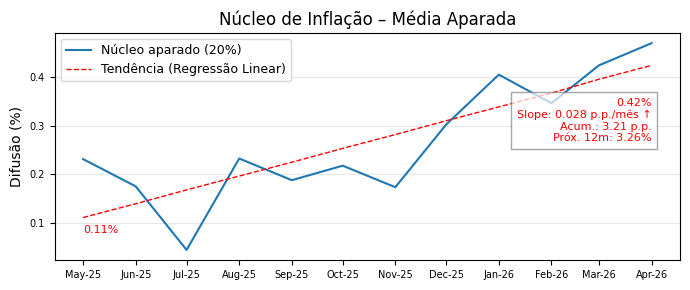

In [7]:
# transformar datas em números (índice)
X = np.arange(len(df_trim)).reshape(-1, 1)
y = df_trim["nucleo_aparado"].values
# modelo de regressão linear (padrão IBM)
modelo = LinearRegression()
modelo.fit(X, y)
# prever valores da tendência
tendencia = modelo.predict(X)
# valores inicial e final
t_ini = tendencia[0]
t_fim = tendencia[-1]
# slope (inclinação da tendência)
slope = modelo.coef_[0]   # p.p. por mês
# acumulado do período (soma das variações mensais)
acumulado = df_trim["nucleo_aparado"].sum()
# projeção anualizada (com base na média mensal)
media_mensal = df_trim["nucleo_aparado"].mean()
proj_12m = (1 + media_mensal/100)**12 - 1
# cor automática
cor_slope = "red" if slope > 0 else "green"
# seta automática
seta = "↑" if slope > 0 else "↓"

plt.figure(figsize=(7, 3))
plt.plot(df_trim["date"], df_trim["nucleo_aparado"], label="Núcleo aparado (20%)", linewidth=1.5)
plt.plot(df_trim["date"], tendencia, "--", color="red", linewidth=1, label="Tendência (Regressão Linear)")

# anotar início
plt.text(df_trim["date"].iloc[0], t_ini - 0.035,
         f"{t_ini:.2f}%", color="red", fontsize=8, ha="left", va="bottom")
# anotar fim
plt.text(df_trim["date"].iloc[-1],
         t_fim - 0.16,
         f"{t_fim:.2f}%\n"
         f"Slope: {slope:.3f} p.p./mês {seta}\n"
         f"Acum.: {acumulado:.2f} p.p.\n"
         f"Próx. 12m: {proj_12m*100:.2f}%",
         color=cor_slope,
         fontsize=8,
         ha="right",
         va="bottom",
          bbox=dict(facecolor="white", alpha=0.7, edgecolor="gray"))

plt.title("Núcleo de Inflação – Média Aparada")
plt.ylabel("Difusão (%)"); plt.tick_params(axis='y', labelsize=7)
plt.xticks(ticks=df_trim["date"], labels=df_trim["date"].dt.strftime("%b-%y"))
plt.tick_params(axis='x', labelsize=7)
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

<br>

---

## ANÁLISE 3 — Heatmap de choques setoriais

Aqui olhamos:
> Quanto cada grupo contribuiu para o IPCA, mês a mês?

In [8]:
query_groups = """
    SELECT
        g.date::date,
        g.grupos,
        (si.indice * (si.peso / 100)) AS contribuicao
    FROM bcb.ipca_subitens si
        LEFT JOIN bcb."vw_groupsBySubItems" g ON g."idSubItens" = si.category AND g.date = si.date;
"""

dfg = pd.read_sql(query_groups, engine)
dfg["date"] = pd.to_datetime(dfg["date"])
df_heat = (
    dfg.groupby(["date", "grupos"])["contribuicao"]
    .sum()
    .reset_index()
    .pivot(index="date", columns="grupos", values="contribuicao")
)
df_heat = df_heat[df_heat.index >= (pd.Timestamp.now() - pd.DateOffset(months=13))]
df_heat.index = df_heat.index.strftime("%b-%y")
df_heat.tail(12)

grupos,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
May-25,0.037919,-0.009633,0.003245,0.035187,0.002912,0.177283,0.073182,-0.075801,0.019037
Jun-25,-0.040587,0.003041,0.005124,0.023599,0.000116,0.148279,0.009191,0.054154,0.034941
Jul-25,-0.057983,0.003256,-0.003942,0.077004,0.001157,0.138198,0.060815,0.070857,-0.025311
Aug-25,-0.099381,-0.003060,-0.004289,0.040578,0.045568,-0.137872,0.072405,-0.055475,0.033366
Sep-25,-0.056618,-0.014280,-0.007791,0.051564,0.004212,0.450019,0.023087,0.002520,0.029237
Oct-25,0.002644,-0.012212,-0.007470,0.045893,0.003466,-0.047312,0.055648,0.022675,0.023722
Nov-25,-0.002213,-0.035237,-0.009021,0.078889,0.000604,0.081164,-0.005534,0.044245,0.022978
Dec-25,0.058288,0.022279,0.016963,0.037535,0.004556,-0.051909,0.070606,0.149510,0.021355
Jan-26,0.049072,0.007006,0.037360,0.041991,0.001136,-0.016557,0.095767,0.121977,-0.011878


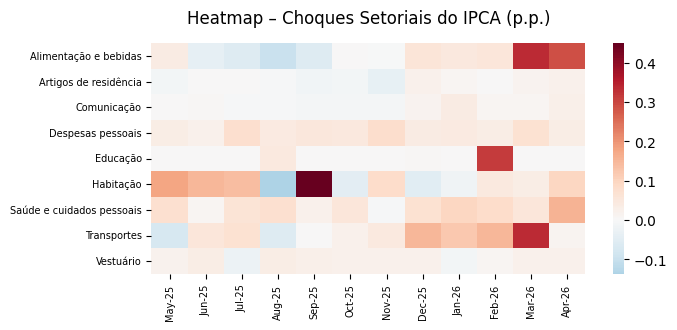

In [9]:
plt.figure(figsize=(7, 3))
sns.heatmap(df_heat.T, cmap="RdBu_r", center=0)
plt.title("Heatmap – Choques Setoriais do IPCA (p.p.)",y=1.05)
plt.ylabel(""), plt.xlabel("")
plt.tick_params(axis='y', labelsize=7)
plt.tick_params(axis='x', labelsize=7)
plt.show()

<br>

---

## ANÁLISE 4 — Persistência inflacionária (momentum)

Momentum responde:
> A inflação está acelerando ou desacelerando?

Usamos uma média móvel de 3 meses.

In [10]:
indice_ipca = """
    SELECT 
        date::date, 
        indice AS ipca
    FROM bcb.ipca
    ORDER BY date
"""

df_ipca = pd.read_sql(indice_ipca, engine)
df_ipca["date"] = pd.to_datetime(df_ipca["date"])

df_ipca["momentum_3m"] = df_ipca["ipca"].rolling(3).mean()
df_ipca = df_ipca[df_ipca["date"] >= (pd.Timestamp.now() - pd.DateOffset(months=13))]
df_ipca.sort_values("date", ascending=False).head(20)

,date,ipca,momentum_3m
556,2026-04-01,0.670000,0.750000
555,2026-03-01,0.880000,0.636667
554,2026-02-01,0.700000,0.453333
553,2026-01-01,0.330000,0.280000
552,2025-12-01,0.330000,0.200000
551,2025-11-01,0.180000,0.250000
550,2025-10-01,0.090000,0.153333
549,2025-09-01,0.480000,0.210000
548,2025-08-01,-0.110000,0.130000
547,2025-07-01,0.260000,0.253333


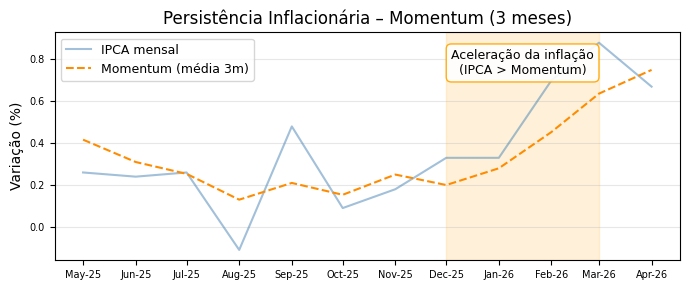

In [11]:
# Aceleração: IPCA > Momentum e momentum não nulo
df_ipca["acelera"] = (df_ipca["ipca"] > df_ipca["momentum_3m"]) & df_ipca["momentum_3m"].notna()
# Se não houver aceleração, não destacamos nada
inicio = fim = None

if df_ipca["acelera"].any():
    # índice do último ponto com aceleração
    last_idx = df_ipca[df_ipca["acelera"]].index.max()
    fim = df_ipca.loc[last_idx, "date"]

    # voltar até onde o bloco contínuo de aceleração começou
    first_idx = last_idx
    while first_idx - 1 in df_ipca.index and df_ipca.loc[first_idx - 1, "acelera"]:
        first_idx -= 1
    inicio = df_ipca.loc[first_idx, "date"]

plt.figure(figsize=(7, 3))
plt.plot(df_ipca["date"], df_ipca["ipca"], label="IPCA mensal", alpha=0.5, color="steelblue")
plt.plot(df_ipca["date"], df_ipca["momentum_3m"], "--", label="Momentum (média 3m)", linewidth=1.5, color="darkorange")

# --- Destacar o último período de aceleração ---
if inicio is not None and fim is not None:
    plt.axvspan(inicio, fim, color="orange", alpha=0.15)
    # Posição do quadro (meio da faixa)
    meio = inicio + (fim - inicio) / 2
    # --- Quadro aceleração ---
    plt.text(meio, df_ipca["ipca"].max() * 0.89,   # posição vertical
        "Aceleração da inflação\n(IPCA > Momentum)", ha="center", va="center", fontsize=9, color="black",
        bbox=dict( boxstyle="round,pad=0.4", facecolor="white", edgecolor="orange", alpha=0.9)
    )

plt.xticks(ticks=df_ipca["date"], labels=df_ipca["date"].dt.strftime("%b-%y"))
plt.tick_params(axis='x', labelsize=7)
plt.tick_params(axis='y', labelsize=7)

plt.title("Persistência Inflacionária – Momentum (3 meses)")
plt.ylabel("Variação (%)")
plt.grid(axis='y', alpha=0.3)
plt.legend(fontsize=9); plt.tight_layout()

plt.show()


## Conclusões

- **Difusão** mostra se a inflação está espalhada entre muitos subitens ou concentrada em poucos.  
- **Núcleo aparado** filtra choques extremos e revela a tendência subjacente da inflação.  
- **Heatmap setorial** mostra, mês a mês, quais grupos mais contribuíram para o IPCA.  
- **Momentum** captura a persistência: se a inflação está acelerando ou perdendo força.

A partir daqui, você pode:
- cruzar essas métricas com SELIC  
- comparar períodos de aperto/afrouxamento monetário  
- construir modelos (VAR, ARIMA, etc.) usando essas séries como insumos.

<br>

---

## Post | Painel de Indicadores de Inflação

### Inflação segundo o IPCA 💡

Com base em dados oficiais do IBGE/SIDRA, integrei quatro indicadores essenciais para revelar o cenário atual da inflação no Brasil.  

1️⃣ Tendência da inflação   
A regressão linear foi aplicada aos indicadores: [difusão, núcleo aparado e momentum] revela um padrão claro:  
 → A difusão segue em tendência de alta, mostrando que a maior parte dos itens do IPCA está subindo ao mesmo tempo.  
 → O núcleo aparado acelera, com slope positivo, indicando pressão inflacionária subjacente.  
 → O momentum de 3 meses aponta períodos de aceleração, quando o IPCA mensal supera a tendência curta.  
▪️ Em termos simples:  
 → A inflação está se espalhando e ganhando persistência.   

2️⃣ Explicando de forma simples  
▪️ Difusão: mede quantos produtos estão ficando mais caros. Acima de 60%, significa que a alta de preços está espalhada, não restrita a um item isolado.  
▪️ Núcleo aparado: remove itens muito voláteis. Se ele sobe, a inflação vem do miolo da economia, não de choques temporários.  
▪️ Momentum: é a velocidade da inflação. Quando o IPCA mensal fica acima do momentum, é como se o carro estivesse acelerando.  
▪️ O que isso significa para o consumidor?  
 → Os preços estão subindo de forma mais ampla e consistente, ganhando força de tendência.  
 → Isso afeta juros, crédito, investimentos e até decisões de política monetária.  

3️⃣ Validação da análise  
▪️ Toda a análise foi construída com dados oficiais extraídos automaticamente da API do IBGE/SIDRA, garantindo:  
 → Atualização em tempo real  
 → Confiabilidade estatística  
 → Reprodutibilidade da metodologia  
 → Transparência total das fontes  
▪️ Essa integração permite atualizar o painel a cada nova divulgação do IPCA, mantendo a leitura sempre atualizada.  
 → Vamos acompanhar juntos os próximos meses e a evolução desse trabalho.  

📌 Conclusão  
O cenário atual mostra uma inflação:  
 → difusa (atinge muitos itens)  
 → persistente (núcleo em alta)  
 → acelerando em momentos-chave (momentum)  
 → com choques setoriais relevantes (heatmap)  

📉 Isso implica:  
 → juros mais altos por mais tempo  
 → maior cautela do Banco Central  
 → impacto direto no custo de vida e nos investimentos  
 → Preços estão subindo de forma mais ampla e consistente, e isso exige atenção.  

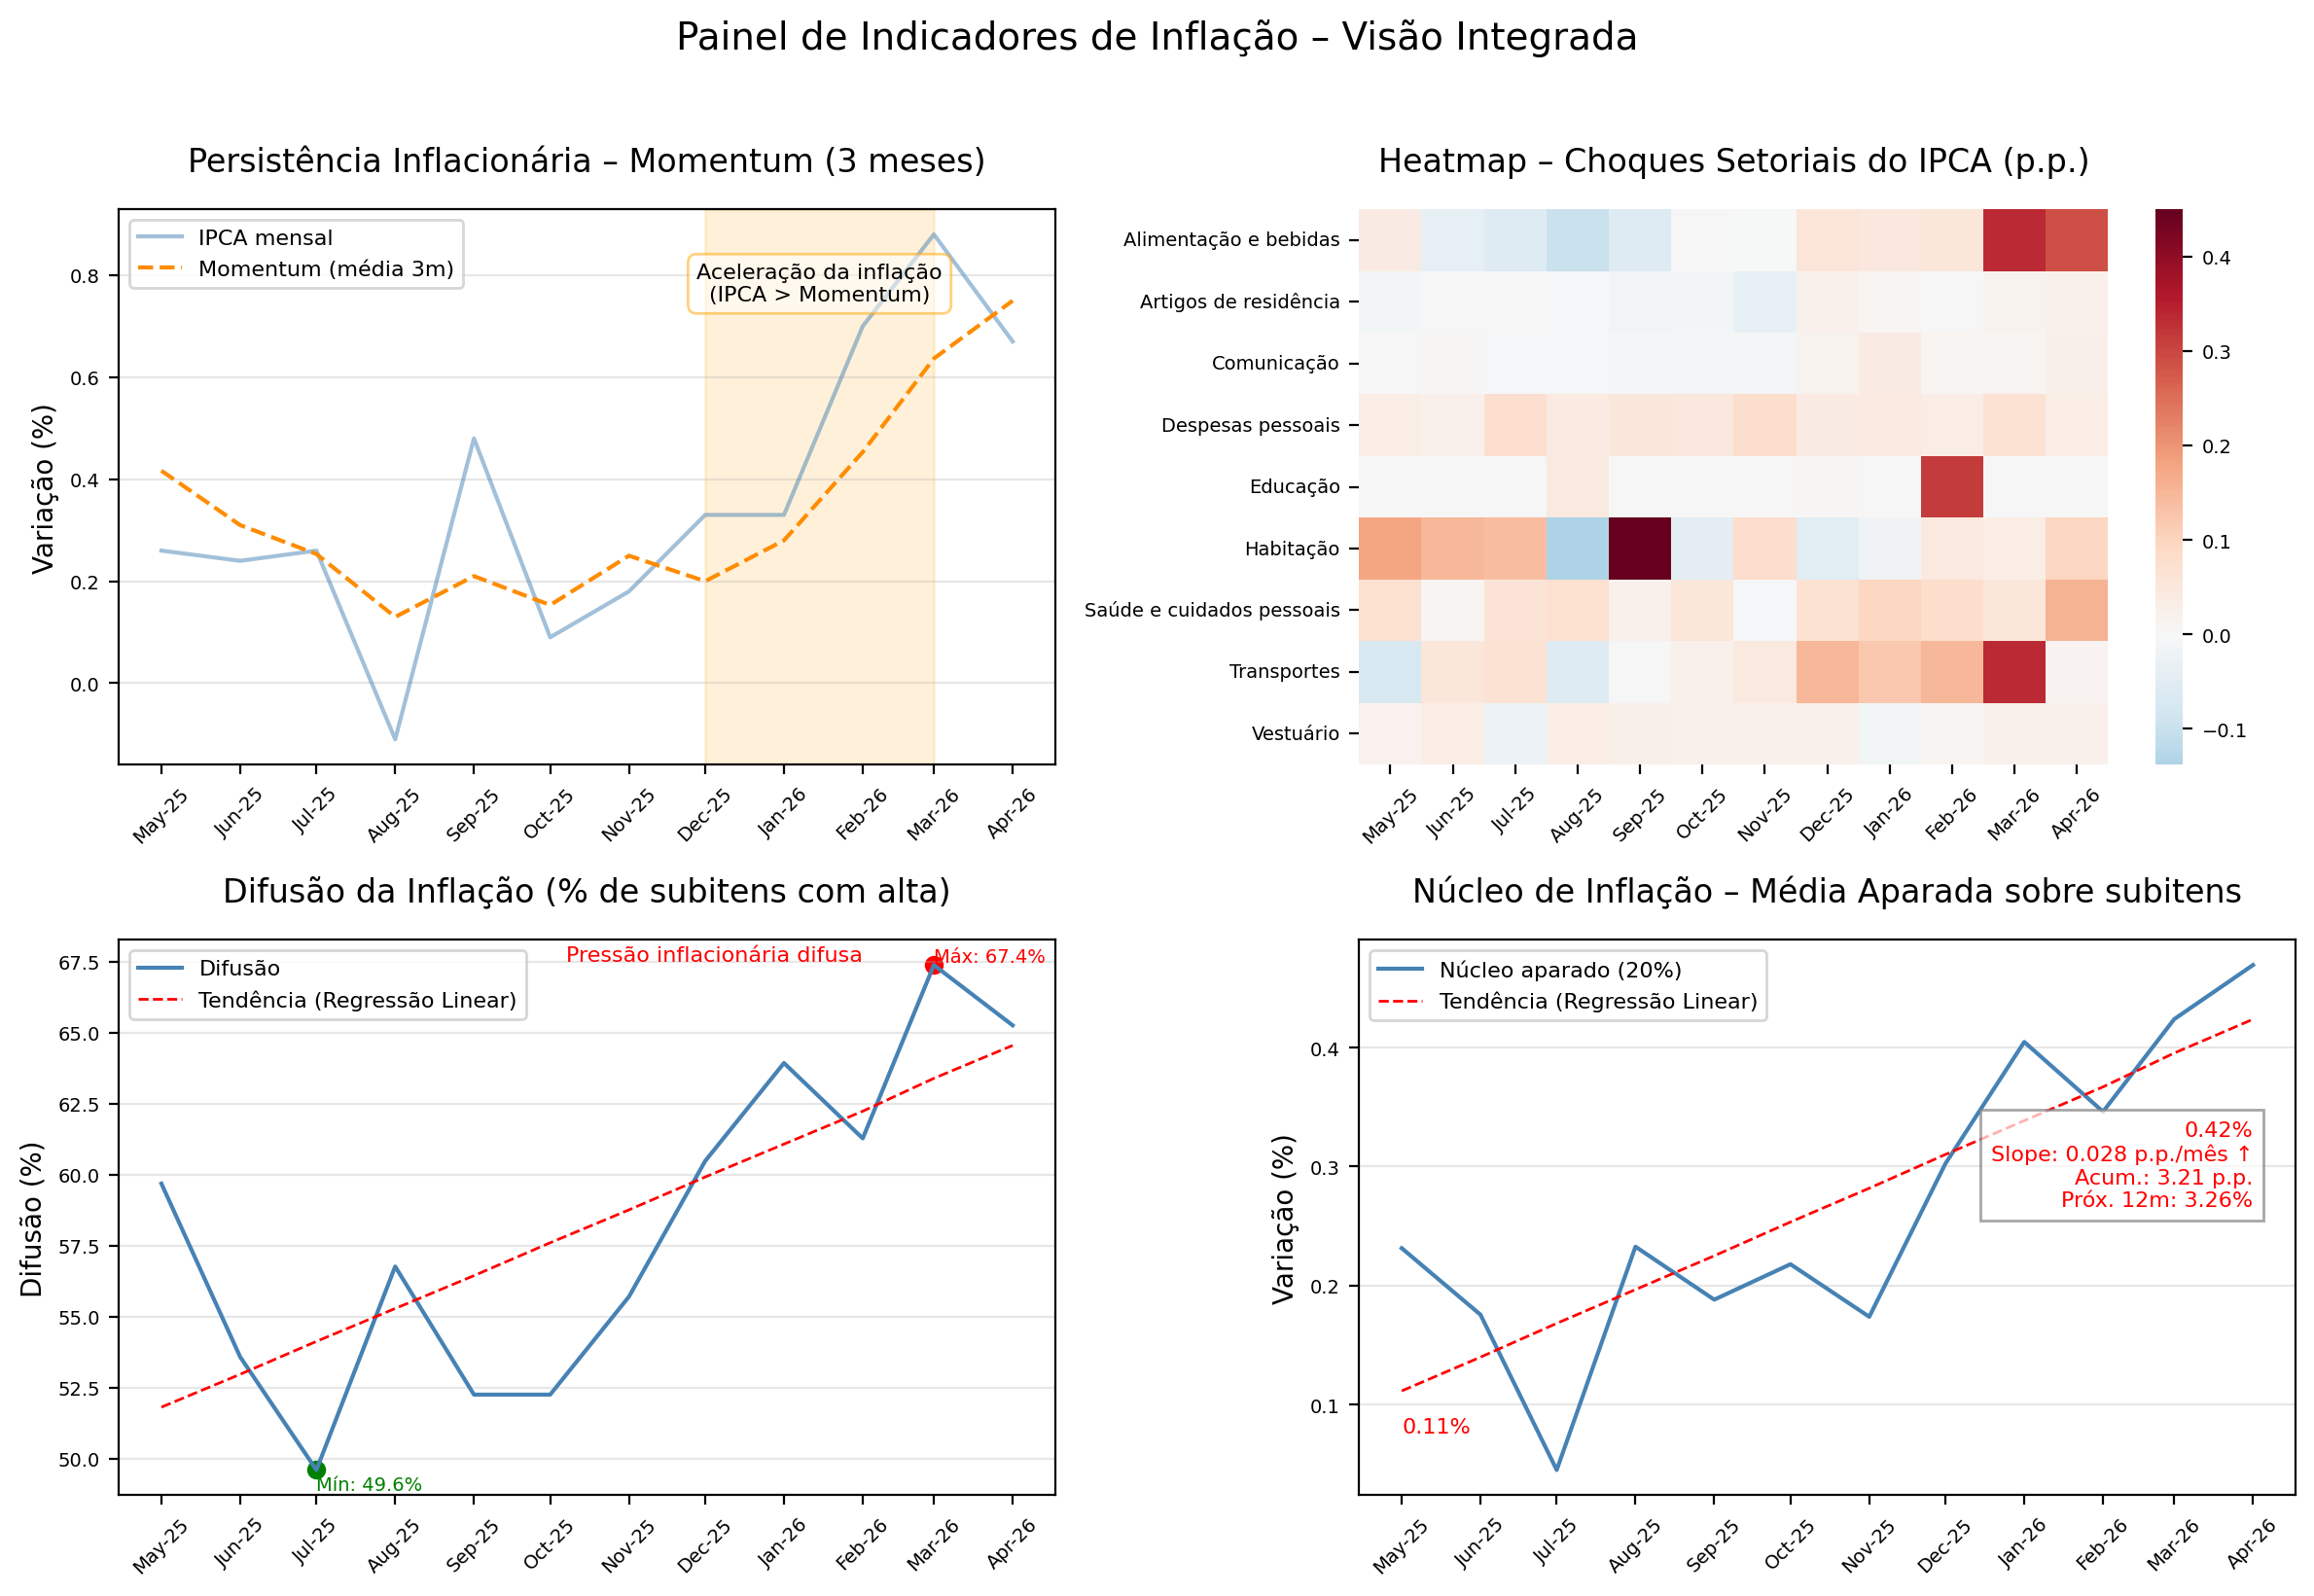

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), dpi=200)

# ============================================================
# 0,0 — DIFUSÃO
# ============================================================

X = np.arange(len(df_difusao)).reshape(-1, 1)
y = df_difusao["difusao"].values
modelo = LinearRegression().fit(X, y)
tendencia = modelo.predict(X)

max_val = df_difusao["difusao"].max()
min_val = df_difusao["difusao"].min()
max_date = df_difusao.loc[df_difusao["difusao"].idxmax(), "date"]
min_date = df_difusao.loc[df_difusao["difusao"].idxmin(), "date"]

ax[1,0].plot(df_difusao["date"], df_difusao["difusao"], linewidth=1.5, color="steelblue", label="Difusão")
ax[1,0].plot(df_difusao["date"], tendencia, "--", color="red", linewidth=1, label="Tendência (Regressão Linear)")
# Máximo e mínimo automáticos
ax[1,0].scatter(max_date, max_val, color="red")
ax[1,0].text(max_date, max_val + 0.1, f"Máx: {max_val:.1f}%", fontsize=7, color="red")
ax[1,0].scatter(min_date, min_val, color="green")
ax[1,0].text(min_date, min_val - 0.7, f"Mín: {min_val:.1f}%", fontsize=7, color="green")

# Alerta automático de difusão alta
if max_val > 60:
    ax[1,0].text(df_difusao["date"].iloc[-3], max_val,
                 "Pressão inflacionária difusa", color="red", fontsize=8,
                 ha="right", va="bottom")

ax[1,0].set_title("Difusão da Inflação (% de subitens com alta)", y=1.04)
ax[1,0].set_ylabel("Difusão (%)"); ax[1,0].tick_params(axis='y', labelsize=7)
ax[1,0].tick_params(axis='x', labelsize=7)
ax[1,0].set_xticks(df_difusao["date"])
ax[1,0].set_xticklabels(df_difusao["date"].dt.strftime("%b-%y"), rotation=45)
ax[1,0].grid(axis="y", alpha=0.3)
ax[1,0].legend(fontsize=8)


# ============================================================
# 1,0 — NÚCLEO APARADO
# ============================================================

X = np.arange(len(df_trim)).reshape(-1, 1)
y = df_trim["nucleo_aparado"].values
modelo = LinearRegression().fit(X, y)
tendencia = modelo.predict(X)

t_ini = tendencia[0]
t_fim = tendencia[-1]
slope = modelo.coef_[0]
acumulado = df_trim["nucleo_aparado"].sum()
media_mensal = df_trim["nucleo_aparado"].mean()
proj_12m = (1 + media_mensal/100)**12 - 1

cor_slope = "red" if slope > 0 else "green"
seta = "↑" if slope > 0 else "↓"

ax[1,1].plot(df_trim["date"], df_trim["nucleo_aparado"], label="Núcleo aparado (20%)", linewidth=1.5, color="steelblue")
ax[1,1].plot(df_trim["date"], tendencia, "--", color="red", linewidth=1, label="Tendência (Regressão Linear)")
ax[1,1].text(df_trim["date"].iloc[0], t_ini - 0.035,
             f"{t_ini:.2f}%", color="red", fontsize=8)
ax[1,1].text(df_trim["date"].iloc[-1],
             t_fim - 0.16,
             f"{t_fim:.2f}%\n"
             f"Slope: {slope:.3f} p.p./mês {seta}\n"
             f"Acum.: {acumulado:.2f} p.p.\n"
             f"Próx. 12m: {proj_12m*100:.2f}%",
             color=cor_slope,
             fontsize=8,
             ha="right",
             va="bottom",
             bbox=dict(facecolor="white", alpha=0.7, edgecolor="gray"))

ax[1,1].set_title("Núcleo de Inflação – Média Aparada sobre subitens", y=1.04)
ax[1,1].set_ylabel("Variação (%)"); ax[1,1].tick_params(axis='y', labelsize=7)
ax[1,1].tick_params(axis='x', labelsize=7)
ax[1,1].set_xticks(df_trim["date"])
ax[1,1].set_xticklabels(df_trim["date"].dt.strftime("%b-%y"), rotation=45)
ax[1,1].grid(axis="y", alpha=0.3)
ax[1,1].legend(fontsize=8)


# ============================================================
# 0,1 — HEATMAP
# ============================================================

sns.heatmap(df_heat.T, cmap="RdBu_r", center=0, ax=ax[0,1])
# Ajustar fonte do termômetro lateral
cbar = ax[0,1].collections[0].colorbar
cbar.ax.tick_params(labelsize=7)
ax[0,1].set_title("Heatmap – Choques Setoriais do IPCA (p.p.)", y=1.04)
ax[0,1].set_ylabel(""); ax[0,1].tick_params(axis='y', labelsize=7)
ax[0,1].set_xlabel(""); ax[0,1].tick_params(axis='x', labelsize=7, rotation=45)

# ============================================================
# 1,1 — MOMENTUM / PERSISTÊNCIA
# ============================================================

df_ipca["acelera"] = (df_ipca["ipca"] > df_ipca["momentum_3m"]) & df_ipca["momentum_3m"].notna()
inicio = fim = None

if df_ipca["acelera"].any():
    last_idx = df_ipca[df_ipca["acelera"]].index.max()
    fim = df_ipca.loc[last_idx, "date"]

    first_idx = last_idx
    while first_idx - 1 in df_ipca.index and df_ipca.loc[first_idx - 1, "acelera"]:
        first_idx -= 1
    inicio = df_ipca.loc[first_idx, "date"]

ax[0,0].plot(df_ipca["date"], df_ipca["ipca"], label="IPCA mensal", alpha=0.5, color="steelblue")
ax[0,0].plot(df_ipca["date"], df_ipca["momentum_3m"], "--", label="Momentum (média 3m)", linewidth=1.5, color="darkorange")

if inicio is not None and fim is not None:
    ax[0,0].axvspan(inicio, fim, color="orange", alpha=0.15)
    meio = inicio + (fim - inicio) / 2
    ax[0,0].text(meio, df_ipca["ipca"].max() * 0.89,
                 "Aceleração da inflação\n(IPCA > Momentum)",
                 ha="center", va="center", fontsize=8,
                 bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="orange", alpha=0.5))

ax[0,0].set_title("Persistência Inflacionária – Momentum (3 meses)", y=1.04)
ax[0,0].set_ylabel("Variação (%)"); ax[0,0].tick_params(axis='y', labelsize=7)
ax[0,0].tick_params(axis='x', labelsize=7)
ax[0,0].set_xticks(df_ipca["date"])
ax[0,0].set_xticklabels(df_ipca["date"].dt.strftime("%b-%y"), rotation=45)
ax[0,0].grid(axis='y', alpha=0.3)
ax[0,0].legend(fontsize=8)


# ============================================================
# TÍTULO GERAL + ALTA RESOLUÇÃO
# ============================================================

fig.suptitle("Painel de Indicadores de Inflação – Visão Integrada", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()